<a href="https://colab.research.google.com/github/YifeiWang-MPVM-200/MPM_200_YifeiWang/blob/MPVM-fall-2026/assignment_1_will__hummers_survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/EpiPandit/MPM_200/blob/main/Session%205/Assignment%201%20-%20Will%20the%20Hummers%20Survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐦 MPM 200 · Week 1 Assignment: *Will the Hummers Survive?*

**Due:** Wednesday 28 October 2026, 9:00 AM · **Total:** 50 points + 5 bonus

**Ground rules**
* Show your work: code **and** output. It lets us follow your thinking and give partial credit.
* Work together, but don't copy. Read each other's code until you could have written it yourself.
* Cells with blanks (`____`) won't run until you fill them in. That's on purpose.

## 📟 Mission briefing

You're the wildlife veterinarian on call for three California wildlife rehabilitation centers. Every year, hummingbirds arrive in shoeboxes and teacups: stunned by windows, carried in by cats, fallen from nests. Some go on to fly again; many don't.

The centers have pooled **more than 25 years of intake records (1991–2016)**. Your mission is to find out **which birds make it back to the sky, and what tips the odds.**

### 🗂️ Case file: data dictionary

| Column | What it records |
|---|---|
| `Admitted` | Date the bird arrived at the center |
| `Disposition_binary` | Outcome: **Died** or **Released** |
| `Place` | Rehabilitation center |
| `F_Aid` | Did the finder give first aid? (Yes/No) |
| `Species_e` | `ANHU` = Anna's Hummingbird · `BCHU` = Black-chinned Hummingbird · `Selasphorus` = orange *Selasphorus* species (e.g., Allen's, Rufous) not identified to species · `Non-selasphorus` = green birds not identified to species |
| `Sex_e`, `Age_e` | Sex and age class as recorded |
| `Brought_in_after` | Days the finder kept the bird before bringing it in |
| `season` | Season of admission |
| `r` | Reason for admission |
| `Green_Orange` | Broad group: green (non-*Selasphorus*) or orange (*Selasphorus*) |
| `ID` | Unique ID for each bird |

## 🍄 Case file 0 · Warm-up: make some noise (2 pts)

**Q0.** Install **beepr** and play the **Mario** sound. Then have a cowsay animal welcome you to the mission (use your name!).

> **Why the helper below?** `beep()` plays sound on the computer *running R*. On Colab that's a Google server with no speakers, so you'd hear nothing. The helper sends the very same sound file to **your browser** instead. On your own laptop, plain `beep("mario")` works.

In [64]:
install.packages(c("beepr", "cowsay"))
library(beepr)
library(cowsay)

# Plays a beepr sound in your browser (for Colab)
beep_colab <- function(sound = "smb_stage_clear") {     # smb_stage_clear = the Mario sound
  wav <- list.files(system.file("sounds", package = "beepr"),
                    pattern = sound, full.names = TRUE)[1]
  b64 <- jsonlite::base64_enc(readBin(wav, "raw", file.info(wav)$size))
  IRdisplay::display_html(sprintf('<audio controls autoplay src="data:audio/wav;base64,%s"></audio>', b64))
}

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [65]:
beep_colab()     # press ▶ if your browser blocks autoplay

say("Welcome to Hummingbird HQ, Dr. Wang!", by = "chicken")


 ______________________________________ 
< Welcome to Hummingbird HQ, Dr. Wang! >
 -------------------------------------- 
      \
       \
         _
       _/ }
      `>' \
      `|   \
       |   /'-.     .-.
        \'     ';`--' .'
         \'.    `'-./
          '.`-..-;`
            `;-..'
            _| _|
            /` /` [nosig]

In [66]:
library(dplyr)
library(ggplot2)
options(repr.plot.width = 7, repr.plot.height = 4.5)
dir.create("outputs", showWarnings = FALSE)

## 📋 Case file 1 · Intake: read the records

**Q1 (2 pts).** Read `Hummingbird_data.csv` into an object called `data`. It lives on the course GitHub, so you can read it straight from the URL.

In [67]:
#url <- "https://raw.githubusercontent.com/EpiPandit/MPM_200/main/data/Hummingbird_data.csv"
data <- read.csv("sample_data/Hummingbird_data.csv")
colnames(data)

[1] "Admitted"           "Disposition_binary" "Place"             
 [4] "F_Aid"              "Species_e"          "Sex_e"             
 [7] "Age_e"              "Brought_in_after"   "season"            
[10] "r"                  "Green_Orange"       "ID"

**Q2 (1 pt).** 🔮 *Predict first:* 26 years, three centers. Guess how many birds: `_7800___`.
Now find how many rows and columns `data` has.

In [68]:
dim(data)
nrow(data)
ncol(data)

[1] 6908   12

[1] 6908

[1] 12

**Q3 (3 pts).** Check the structure of the data.
* Use `str()` to see each column.
* Use `sapply()` with `class` to list every column's data type.
* Which columns are text (`character`) and which are numbers? Is `Admitted` stored as a date? Note anything that looks odd.

In [69]:
str(data)

data_types <- sapply(data, class)
print(data_types)

'data.frame':	6908 obs. of  12 variables:
 $ Admitted          : chr  "1/2/1991" "1/2/1991" "1/4/1991" "1/5/1991" ...
 $ Disposition_binary: chr  "Died" "Released" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "Yes" "No" "No" ...
 $ Species_e         : chr  "ANHU" "ANHU" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  1 0 0 4 0 0 0 0 0 0 ...
 $ season            : chr  "Winter" "Winter" "Winter" "Winter" ...
 $ r                 : chr  "found on the ground" "unknown" "suspect torpor-like state" "unknown" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "1_ANHU" "2_ANHU" "3_ANHU" "4_ANHU" ...
          Admitted Disposition_binary      

✍️ **Your answer:** Admitted, Disposition_binry, Place, F_Aid, Spciese_e, Sex_e, Age_e, season, r, Green_Orange and ID are text character, while only Brought_in_after is integer. Admitted is not sorted as a data.

### 🎲 Draw your own reproducible sample
Each of you will analyse a random sample of 5,000 birds. `set.seed()` makes "random" **repeatable**: the same seed always gives the same sample, so your instructor can reproduce your results exactly (remember the reproducibility checklist from lecture?).

👉 Replace `1225` with **your birthday as MMDD** (e.g., 3 July → `0703`, which R reads as 703).

In [70]:
set.seed(0303)                              # ← your birthday, MMDD
model_data <- slice_sample(data, n = 5000)

**Use `model_data` for the rest of the assignment.**

**Q4 (1 pt).** How many rows and columns does `model_data` have?

In [71]:
dim(model_data)
nrow(model_data)
ncol(model_data)

[1] 5000   12

[1] 5000

[1] 12

**Q5 (2 pts).** How many columns are **categorical** and how many are **continuous**? Name the continuous one(s). Is `ID` a useful variable for analysis?

In [72]:
str(model_data)

'data.frame':	5000 obs. of  12 variables:
 $ Admitted          : chr  "4/8/2010" "3/21/2016" "4/30/1999" "4/10/2000" ...
 $ Disposition_binary: chr  "Released" "Released" "Released" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "Yes" "No" "No" ...
 $ Species_e         : chr  "ANHU" "ANHU" "Selasphorus" "ANHU" ...
 $ Sex_e             : chr  "Male" "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  0 0 0 0 1 0 0 0 1 0 ...
 $ season            : chr  "Spring" "Spring" "Spring" "Spring" ...
 $ r                 : chr  "found inside" "found on the ground" "caught by domestic animal" "window hit" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "3907_ANHU" "5543_ANHU" "1618_ALHU" "1792_ANHU" ...


✍️ **Your answer:** I think there are 11 categorical and 1 continuous which is Brought_in_afer. ID is useful for identifying individual records and checking for duplicates.

**Q6 (2 pts).** Save your sample as `Hummingbird_data_YOURNAME.csv` in the `outputs` folder, and submit it. Use `row.names = FALSE`.

In [73]:
write.csv(model_data, "outputs/Hummingbird_data_YifeiWang.csv", row.names = FALSE)

## 🏥 Case file 2 · Which hospital is busiest?

Let's count how many birds each center admitted (column `Place`), using dplyr to build a summary table and ggplot2 to plot it.

In [74]:
rehab <- model_data %>%
  group_by(Place) %>%
  summarise(count = n_distinct(ID))
rehab

Place,count
<chr>,<int>
Lindsey,4152
Santa Barbara,68
malibu,780


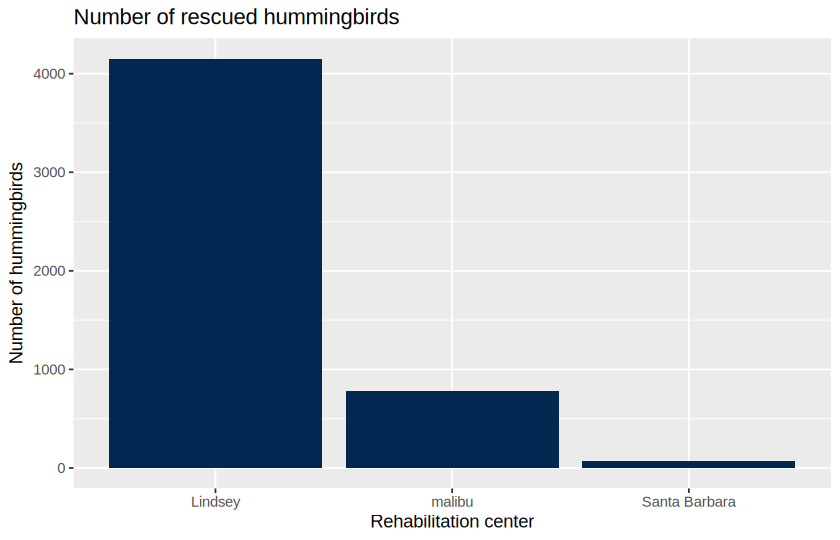

In [75]:
p <- ggplot(rehab, aes(x = Place, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds") +
  labs(title = "Number of rescued hummingbirds")
p

**Q7 (2 pts).** Save this plot as a **PDF, 4 inches wide and 3 inches tall**, and submit it.

In [76]:
ggsave("outputs/rehab_counts_YOURNAME.pdf", p, width = 4, height = 3)

**Q8 (3 pts).** Explain the code in words, line by line, from the line that creates `rehab` through the plot. What does each function do?

✍️ **Your answer:** \
rehab <- model_data: it takes model_data as the input dataset, and saves the final result as a new data frame called rehab.\
%>%: it passes the result to the next function.\
group_by(Place): it groups the data by rehabilitation center.\
summarise(count = n_distinct(ID)): Counts the number of unique hummingbird IDs in each rehabilitation center and stores the results in a new column called count.\
rehab: It displays the summarized data frame.\
p <- ggplot(rehab, aes(x=Place, y=count)): It creats a plot using the rehab data frame, with rehabilitation centrs on the x-axis and the number of hummingbird on the y-axis. The plot is sorted in p.\
geom_col(fill = "#022851"): It creates a bar chart and fills the bars with the color #022851 which is Aggie Blue.\
xlab("Rehabilitation center"): It sets the label of the x-axis.\
ylab("Number of hummingbirds"): It sets the label of the y-axis.\
labs(title = "Number of rescued hummingbirds"): It adds a title to the plot.\
p: It displays the final plot.

**Q9 (2 pts).** 🤔 Lindsey admitted far more birds than the other centers. Does that mean more birds **die** at Lindsey? Why are raw counts not enough to compare outcomes between centers?

✍️ **Your answer:** No. Lindsey admitted more birds than the other centers, but this does not mean more birds died there. We should calculate the mortality proportion by dividing the number of birds that died by the total number of birds admitted to each center to tell which center has high died hummingbirds proportion. Since hummingbirds in different admitted center are different from species, age, and health condition, which can influence mortality proportion of hummingbirds, we can not simply use raw counts to compare outcomes between centers.

## 🔬 Case file 3 · Who survives?

**Q10 (6 pts).** Pick **three** variables you think could affect survival (e.g., `F_Aid`, `Age_e`, `r`, `season`, `Sex_e`, `Species_e`).
For **each** variable:
1. Make a table counting unique birds (`ID`) for every combination of the variable and `Disposition_binary`.
2. Plot it as bars, split into panels with `facet_grid()`.

Copy the two cells below for each variable.

In [77]:
df <- model_data %>%
  group_by(Age_e, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

Age_e,Disposition_binary,count
<chr>,<chr>,<int>
Nestling,Died,422
Nestling,Released,787
adult-like,Died,2765
adult-like,Released,1026


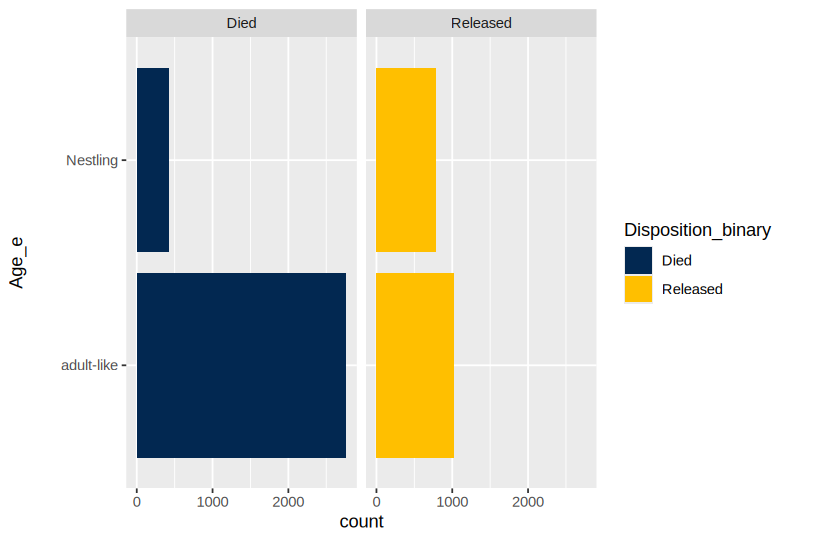

In [78]:
ggplot(df, aes(x = Age_e , y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

In [79]:
df <- model_data %>%
  group_by(Sex_e, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

Sex_e,Disposition_binary,count
<chr>,<chr>,<int>
Female-like,Died,2316
Female-like,Released,907
Male,Died,441
Male,Released,119
unknown,Died,430
unknown,Released,787


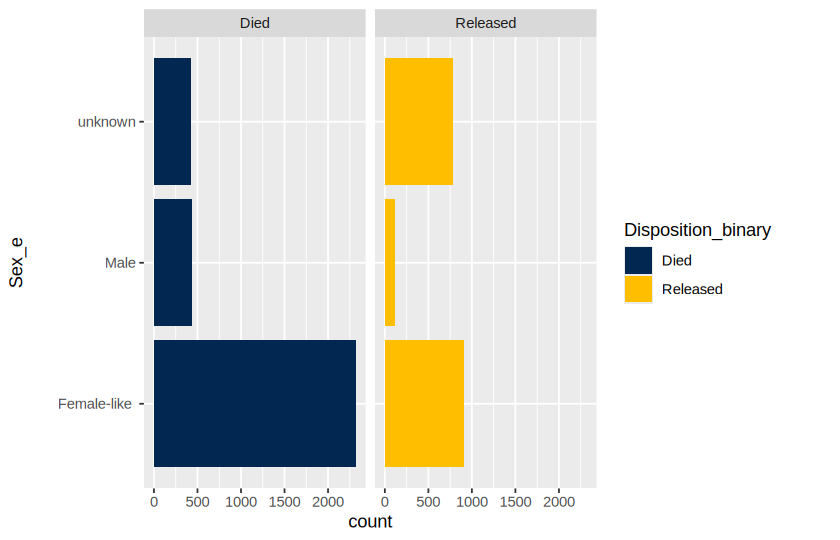

In [80]:
ggplot(df, aes(x = Sex_e , y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

In [81]:
df <- model_data %>%
  group_by(Species_e, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

Species_e,Disposition_binary,count
<chr>,<chr>,<int>
ANHU,Died,2269
ANHU,Released,827
BCHU,Died,22
BCHU,Released,16
Non-selasphorus,Died,353
Non-selasphorus,Released,645
Selasphorus,Died,543
Selasphorus,Released,325


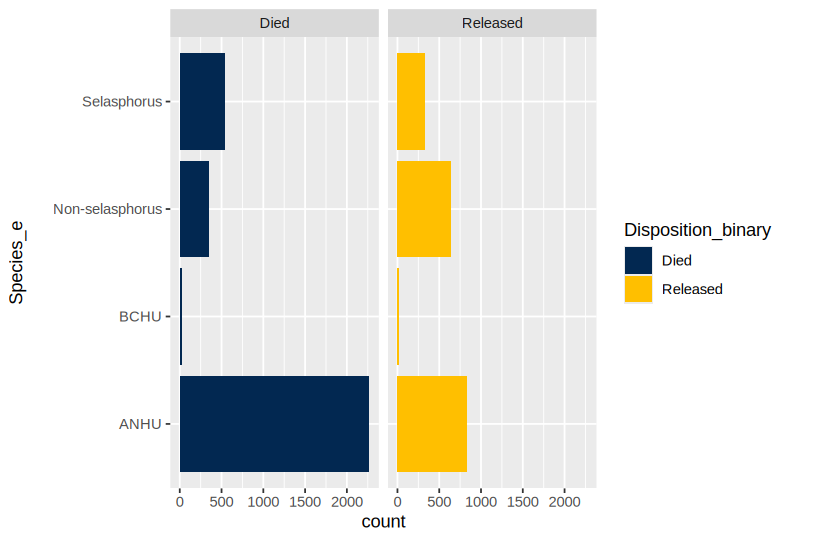

In [82]:
ggplot(df, aes(x = Species_e , y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

**Q11 (4 pts).** What do your tables and plots suggest? Which variables look associated with the outcome? Which **statistical test** could check whether the association is more than chance?


✍️ **Your answer:** Based on the tables and plots, adult-like hummingbirds, male hummingbirds, and ANHU hummingbirds appear to have higher proportions of death within their respective groups. These results suggest that age, sex, and species may all be associated with the outcome. However, raw counts alone are not sufficient because the sample sizes differ among categories. Since both the explanatory variables and the outcome are categorical, a chi-square test of independence could be used to determine whether these associations are statistically significant.

### 📊 From counts to proportions
**Q12 (5 pts).** Calculate the proportion of birds **released vs. died** at each center, show the table, and plot it as side-by-side bars.

Place,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Lindsey,Died,2664,0.6416185
Lindsey,Released,1488,0.3583815
Santa Barbara,Died,40,0.5882353
Santa Barbara,Released,28,0.4117647
malibu,Died,483,0.6192308
malibu,Released,297,0.3807692


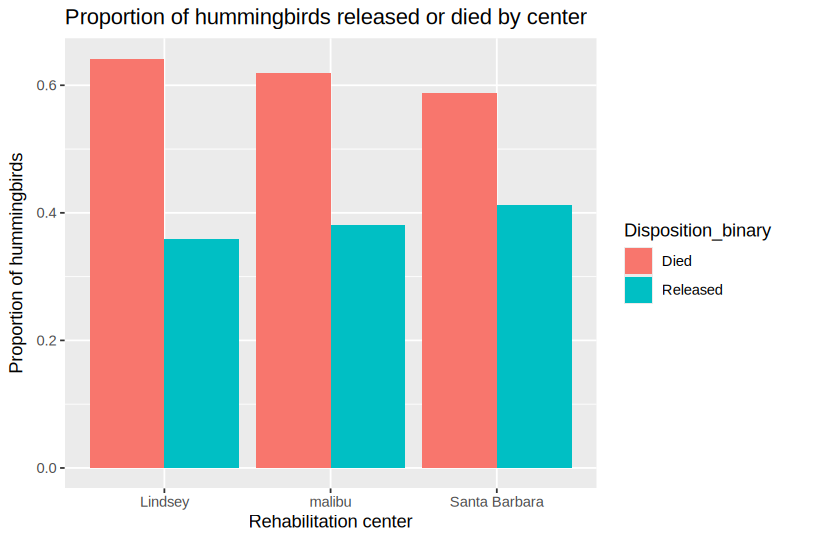

In [83]:
proportions <- model_data %>%
  group_by(Place, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Place) %>%
  mutate(proportion = count / sum(count))
proportions

ggplot(proportions, aes(x = Place, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  xlab("Rehabilitation center") +
  ylab("Proportion of hummingbirds") +
  labs(title = "Proportion of hummingbirds released or died by center")

## 🧬 Case file 4 · Green birds vs. orange birds

**Q13 (5 pts).** Make a new column `Species_group` with two groups:
* **`Selasphorus`**: all *Selasphorus* birds
* **`Non-selasphorus`**: Anna's (ANHU), Black-chinned (BCHU) and unidentified non-*Selasphorus* birds

Then tabulate and plot survival by `Species_group`. **Do survival proportions differ between the groups?**

✅ *Check yourself:* the dataset already has a `Green_Orange` column. If your grouping is right, `table(model_data$Species_group, model_data$Green_Orange)` has zeros off the diagonal.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

There is only **one** value that belongs in the `Selasphorus` group, so a single `ifelse()` does it: *if* `Species_e` is `"Selasphorus"`, then `"Selasphorus"`, *else* `"Non-selasphorus"`.

</details>

                
                 Non-selasphorus spp. Selasphorus spp.
  Non-selasphors                 4132                0
  Selaphorus                        0              868

Species_group,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Non-selasphors,Died,2644,0.6398838
Non-selasphors,Released,1488,0.3601162
Selaphorus,Died,543,0.6255760
Selaphorus,Released,325,0.3744240


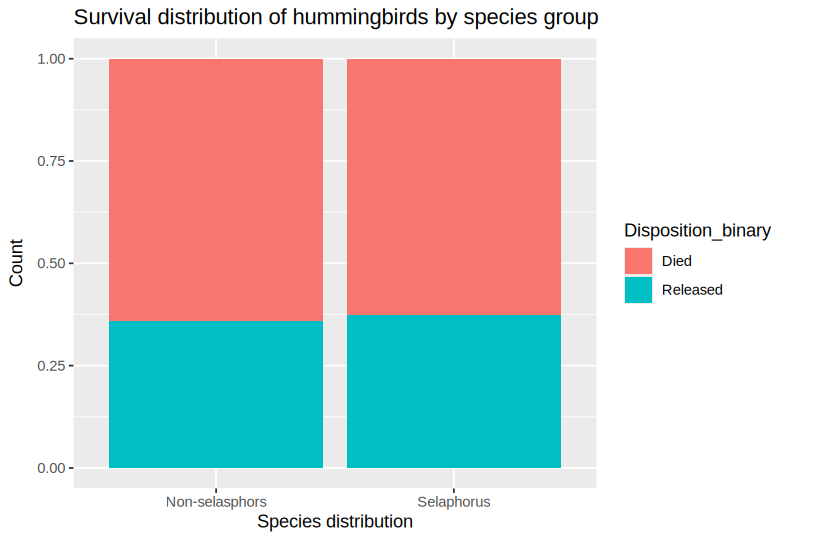

In [84]:
model_data$Species_group <- ifelse(model_data$Species_e == "Selasphorus", "Selaphorus", "Non-selasphors")

table(model_data$Species_group, model_data$Green_Orange)   # self-check

species_distribution <- model_data %>%
  group_by(Species_group, Disposition_binary) %>%
  summarise(count = n_distinct(ID),.groups = "drop")%>%
  group_by(Species_group)%>%
  mutate(proportion = count / sum(count))
species_distribution

ggplot(species_distribution, aes(x =Species_group, y = proportion, fill = Disposition_binary)) +
  geom_col() +
  xlab("Species distribution") +
  ylab("Count") +
  labs(title = "Survival distribution of hummingbirds by species group")

✍️ **Your answer:** The survival proportions are very similar between the two species groups. Selasphorus birds have a slightly higher survival proportion (37.44%) than Non-selasphorus birds (36.01%). However, the difference is small.

## ⏳ Case file 5 · Time traveller: admissions over the years

**Q14 (2 pts).** Convert `Admitted` to a real date. Then explain what the `format` argument does, and what would happen if you used `"%d/%m/%Y"` instead.

In [85]:
model_data$Admitted_date <- as.Date(model_data$Admitted, format = "%m/%d/%Y")
class(model_data$Admitted_date)
range(model_data$Admitted_date)

[1] "Date"

[1] "1991-01-02" "2016-12-28"

✍️ **Your answer:** The format argument tells R how to interpret the original date string. In this dataset, the dates are recorded in month/day/year format, so %m/%d/%Y should be used. If %d/%m/%Y were used instead, R would interpret the month as the day and the day as the month. As a result, some dates would be incorrect, while others would become missing values (NA) because the month would be invalid.

**Q15 (4 pts).** 🔮 *Predict first:* which **season** do you think brings the most hummingbirds into care? `__winter__` Why? In the winter, food becomes hard to find and the temperature becomes lower, so it is hard for hummingbirds to survive.

Now count admissions per **month** and per **year**, and plot both timelines. Was your season prediction right? (`table(model_data$season)` will tell you.)

In [86]:
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%Y-%m")) %>%
  group_by(Admitted_month) %>%
  summarise(count = n())

admissions_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year) %>%
  summarise(count=n())

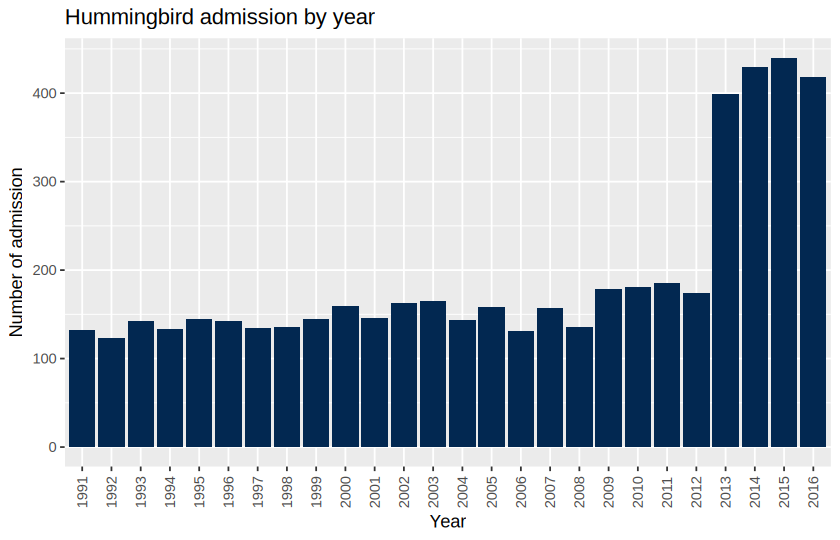

In [87]:
ggplot(admissions_by_year, aes(x = Admitted_year, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Year") +
  ylab("Number of admission") +
  labs(title = "Hummingbird admission by year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

## now plot admissions_by_month the same way

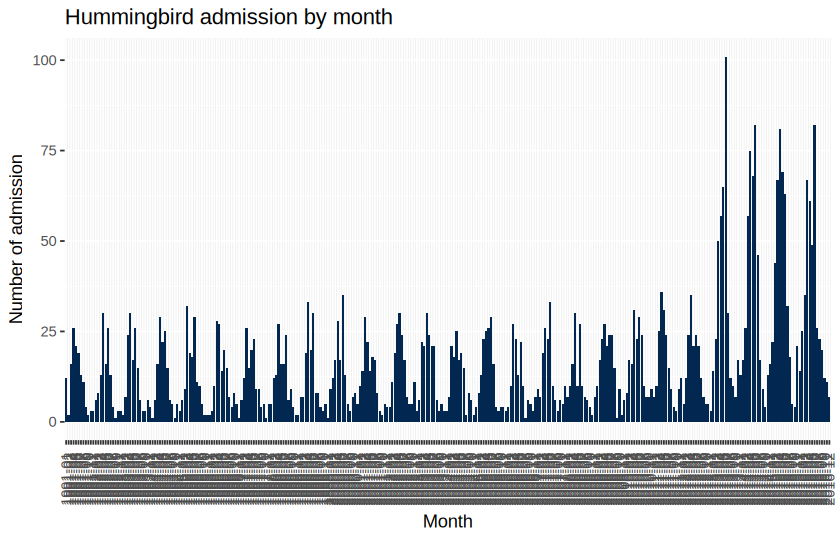

In [88]:
ggplot(admissions_by_month, aes(x = Admitted_month, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Month") +
  ylab("Number of admission") +
  labs(title = "Hummingbird admission by month") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

**Q16 (2 pts).** 🕵️ **Plot twist.** Admissions roughly **triple** from 2013 onwards. Did hummingbirds suddenly get into three times more trouble? Find out what really changed.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Count admissions by year **and** `Place`: `model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)`. When does each center first appear?

</details>

In [89]:
model_data %>%
  filter(format(Admitted_date, "%Y") == "2013") %>%
  group_by(Disposition_binary) %>%
  summarise(count = n()) %>%
  mutate(proportion = count / sum(count))

Disposition_binary,count,proportion
<chr>,<int>,<dbl>
Died,251,0.6290727
Released,148,0.3709273


In [90]:
model_data %>%
  mutate(period = ifelse(format(Admitted_date, "%Y") < "2013",
                         "Before 2013", "2013 onwards")) %>%
  group_by(period, Disposition_binary) %>%
  summarise(count = n(), .groups = "drop") %>%
  group_by(period) %>%
  mutate(proportion = count / sum(count))

period,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
2013 onwards,Died,1065,0.6312982
2013 onwards,Released,622,0.3687018
Before 2013,Died,2122,0.6405071
Before 2013,Released,1191,0.3594929


In [91]:
table(format(model_data$Admitted_date, "%Y"),
      model_data$Place)

      
       Lindsey malibu Santa Barbara
  1991     132      0             0
  1992     123      0             0
  1993     143      0             0
  1994     134      0             0
  1995     145      0             0
  1996     142      0             0
  1997     135      0             0
  1998     136      0             0
  1999     145      0             0
  2000     159      0             0
  2001     146      0             0
  2002     163      0             0
  2003     165      0             0
  2004     144      0             0
  2005     158      0             0
  2006     131      0             0
  2007     157      0             0
  2008     136      0             0
  2009     179      0             0
  2010     181      0             0
  2011     185      0             0
  2012     173      1             0
  2013     185    214             0
  2014     212    218             0
  2015     250    190             0
  2016     193    157            68

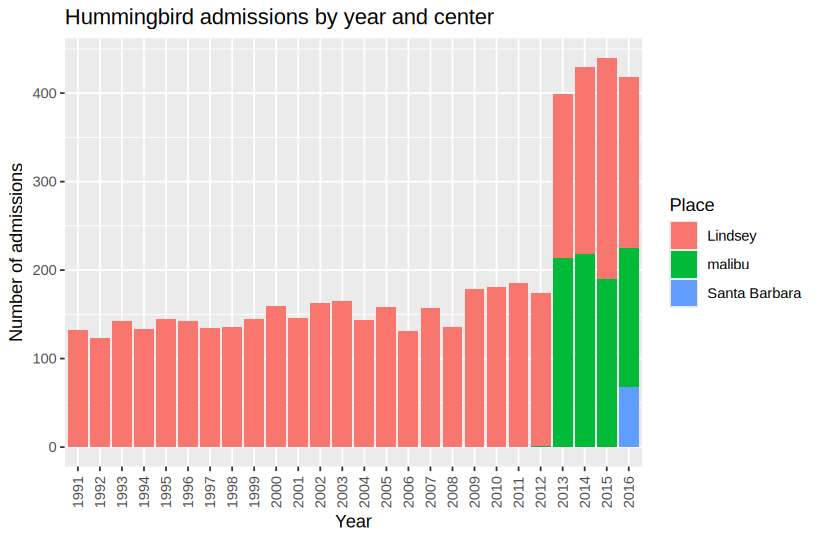

In [92]:
admissions_by_center <- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year, Place) %>%
  summarise(count = n(), .groups = "drop")

ggplot(admissions_by_center,
       aes(x = Admitted_year, y = count, fill = Place)) +
  geom_col() +
  xlab("Year") +
  ylab("Number of admissions") +
  labs(title = "Hummingbird admissions by year and center") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

✍️ **Your answer:** After examining the number of admissions by year and rehabilitation center, I found that records from the Malibu rehabilitation center started to appear in the dataset in 2013. The sharp increase in admissions can be explained. So it doesn't mean a sudden increase in the number of hummingbirds are in trouble.

## 🕵️ Bonus · Data detective (+5 pts)

Real data are messy, and these data have **at least three problems** hiding in the *raw* file (`data`). Find three, show the code that reveals each one, and say how you would fix it **without overwriting the raw file**.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Try `summary(data$Brought_in_after)`, `unique(data$Sex_e)` (look *very* closely at the spaces), and `unique(data$Place)` (look at capitalisation).

</details>

In [93]:
# your detective work here

✍️ **Your answer:**

## 💭 Debrief (2 pts)

**Q17.** In two or three sentences: (a) one thing in this data that surprised you, and (b) one R error you hit and how you fixed it.

✍️ **Your answer:** What surprised me most was the sharp increase in hummingbird admissions in 2013, especially when I discovered that it was partly due to the inclusion of records from another rehabilitation center. \
One error I frequently encountered in R was using incorrect object or column names because I often got confused when creating new variables and data frames. I fixed these errors by checking the original column names and reviewing my previous code, although I still find it challenging to translate my understanding of the analytical process into R code.

## 🎨 Hall of Fame (optional, not graded)
Make your **most beautiful** plot from this dataset, in Aggie Blue `#022851` and Aggie Gold `#FFBF00`. The best ones get shown in class. 🏆

## 📤 How to submit
1. Run every cell from the top (**Runtime → Restart and run all**) so the outputs are fresh.
2. Save the notebook to **your branch** of the course GitHub repo: File → Save a copy in GitHub (**never `main`**).
3. Download and submit `Hummingbird_data_YOURNAME.csv` and `rehab_counts_YOURNAME.pdf` from `outputs/`.

In [94]:
beep_colab("smb_stage_clear")   # mission complete 🍄